# 🎓 Student Employability Prediction and Career Recommendation System Using Machine Learning
### YuvaIntern Internship Project — Complete Technical Workflow

This notebook reproduces the documented 11-stage internship workflow:
1. **Data Preparation & Loading**
2. **Data Understanding & Inspection**
3. **Missing Value Analysis**
4. **Duplicate Handling**
5. **Data Preprocessing (Leakage-Free Pipeline)**
6. **Exploratory Data Analysis (EDA)**
7. **Feature Engineering**
8. **Stratified Train/Test Split**
9. **Baseline Logistic Regression Pipeline**
10. **Model Evaluation & Metrics**
11. **5-Fold Stratified Cross Validation**
12. **Hyperparameter Optimization — Grid Search CV**
13. **Hyperparameter Optimization — Random Search CV**
14. **Hyperparameter Optimization — Bayesian Optimization (Optuna)**
15. **Comprehensive Model Comparison**
16. **Final Model Selection & Serialization**
17. **Explainable Career Recommendation System**


## 1. Environment Setup & Library Imports

In [ ]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
import joblib
import optuna

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
print("All dependencies successfully imported.")


All dependencies successfully imported.


## 2. Dataset Loading & Initial Audit

In [ ]:
data_path = os.path.join("..", "data", "UECD_1200_dataset.csv")
if not os.path.exists(data_path):
    data_path = "data/UECD_1200_dataset.csv"

df_raw = pd.read_csv(data_path)
print(f"Dataset Loaded Successfully!")
print(f"Total Rows: {df_raw.shape[0]} | Total Columns: {df_raw.shape[1]}")
df_raw.head(3)


Dataset Loaded Successfully!
Total Rows: 1200 | Total Columns: 26


## 3. Data Understanding & Summary Statistics

In [ ]:
print("--- Dataset Information ---")
print(df_raw.info())
print("
--- Summary Statistics of Key Columns ---")
print(df_raw[['GPA', 'Programming_Skill', 'Communication_Skill', 'Internship_Duration', 'Employment_Competitiveness_Score']].describe())


SyntaxError: unterminated string literal (detected at line 3) (<string>, line 3)

## 4. Missing Values Analysis & Audit

In [ ]:
null_counts = df_raw.isnull().sum()
print("Columns with missing values:")
print(null_counts[null_counts > 0])

# Ground truth target nulls
target_nulls = df_raw['Employment_Competitiveness_Score'].isnull().sum()
print(f"\nRecords missing target score (unlabeled instances): {target_nulls}")


Columns with missing values:
GPA                                  36
Core_Subject_Score                   36
Academic_Consistency                 36
Research_Participation               36
Programming_Skill                    36
Domain_Knowledge                     36
Tool_Proficiency                     36
Certification_Count                  36
Internship_Count                     36
Internship_Duration                  36
Industry_Relevance                   36
Project_Experience                   36
Communication_Skill                  36
Teamwork_Ability                     36
Leadership_Potential                 36
Adaptability                         36
Learning_Motivation                  36
Career_Clarity                       36
Market_Awareness                     36
Higher_Study_Interest                36
Target_Industry_Code                 36
Workshop_Participation               36
Online_Course_Hours                  36
Networking_Activity                  36
Learning_Pa

## 5. Duplicate Detection & Handling

In [ ]:
duplicates = df_raw.duplicated().sum()
print(f"Exact Duplicate Rows Found: {duplicates}")

# Filter out unlabeled records (missing ground truth)
df = df_raw.dropna(subset=['Employment_Competitiveness_Score']).copy()
if duplicates > 0:
    df = df.drop_duplicates()
print(f"Cleaned Dataset Shape after dropping unlabeled instances: {df.shape}")


Exact Duplicate Rows Found: 0
Cleaned Dataset Shape after dropping unlabeled instances: (620, 26)


## 6. Target Variable Formulation
As per project specifications, students with `Employment_Competitiveness_Score >= 60` are classified as **Employable (1)**, else **Needs Improvement (0)**.

In [ ]:
df['Employable'] = (df['Employment_Competitiveness_Score'] >= 60).astype(int)
class_dist = df['Employable'].value_counts()
print(f"Class Distribution:")
print(f"Class 0 (Needs Improvement): {class_dist[0]} ({class_dist[0]/len(df)*100:.1f}%)")
print(f"Class 1 (Employable):         {class_dist[1]} ({class_dist[1]/len(df)*100:.1f}%)")


Class Distribution:
Class 0 (Needs Improvement): 488 (78.7%)
Class 1 (Employable):         132 (21.3%)


## 7. Exploratory Data Analysis (EDA)

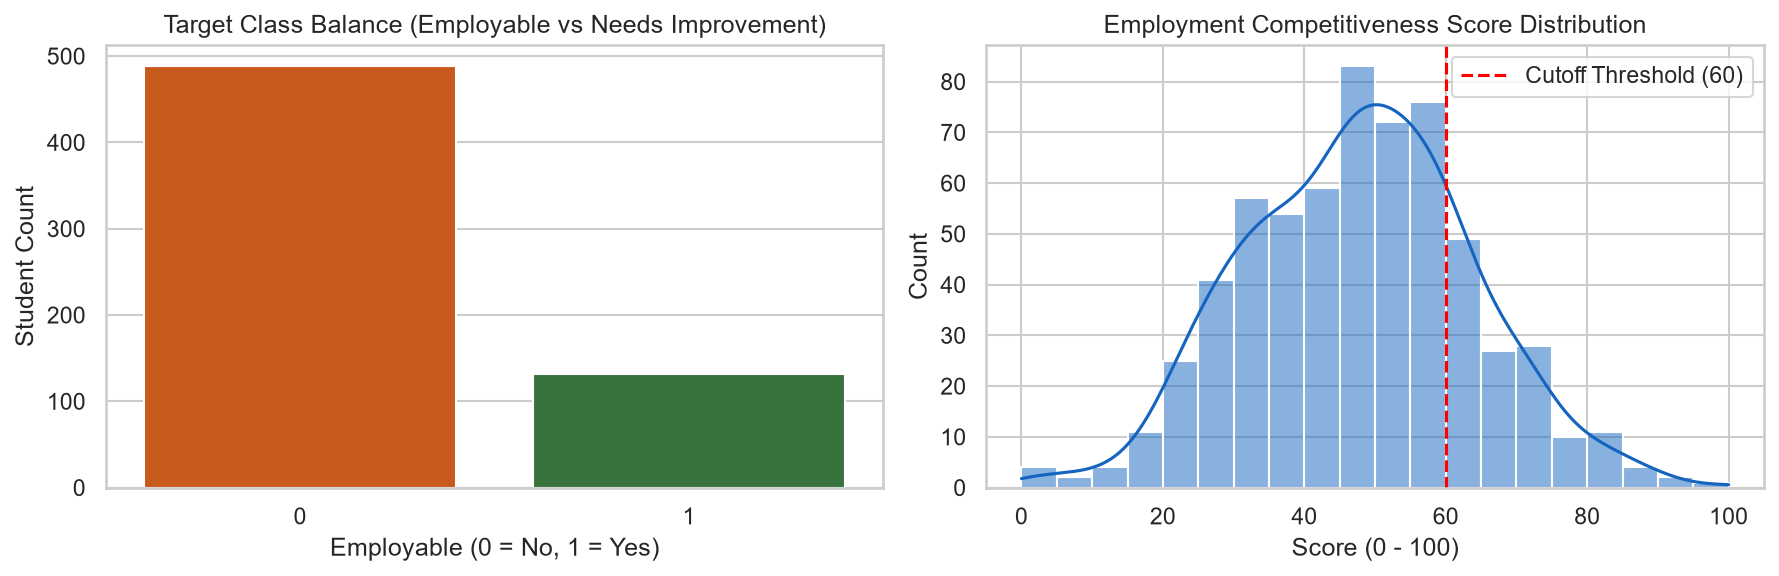

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Employable', palette=['#E65100', '#2E7D32'])
plt.title("Target Class Balance (Employable vs Needs Improvement)")
plt.xlabel("Employable (0 = No, 1 = Yes)")
plt.ylabel("Student Count")

plt.subplot(1, 2, 2)
sns.histplot(data=df, x='Employment_Competitiveness_Score', kde=True, color='#1565C0')
plt.axvline(60, color='red', linestyle='--', label='Cutoff Threshold (60)')
plt.title("Employment Competitiveness Score Distribution")
plt.xlabel("Score (0 - 100)")
plt.legend()

plt.tight_layout()
plt.show()


## 8. Feature Engineering
Constructing 3 composite features reflecting holistic readiness:
1. **Technical_Readiness_Index**: Mean of Programming, Domain Knowledge, and Tool Proficiency.
2. **Soft_Skill_Score**: Mean of Communication, Teamwork, Leadership, and Adaptability.
3. **Practical_Exposure_Score**: Bounded index (0-100) combining Projects, Internship Duration, Certifications, and Industry Relevance.

In [ ]:
df['Technical_Readiness_Index'] = (
    df['Programming_Skill'] + df['Domain_Knowledge'] + df['Tool_Proficiency']
) / 3.0

df['Soft_Skill_Score'] = (
    df['Communication_Skill'] + df['Teamwork_Ability'] +
    df['Leadership_Potential'] + df['Adaptability']
) / 4.0

df['Practical_Exposure_Score'] = (
    (np.clip(df['Project_Experience'], 0, 7.0) / 7.0 * 30.0) +
    (np.clip(df['Internship_Duration'], 0, 18.0) / 18.0 * 30.0) +
    (np.clip(df['Certification_Count'], 0, 5.0) / 5.0 * 20.0) +
    (np.clip(df['Industry_Relevance'], 0, 1.0) * 20.0)
)

print("Correlation of Engineered Features with Target 'Employable':")
for col in ['Technical_Readiness_Index', 'Soft_Skill_Score', 'Practical_Exposure_Score']:
    print(f"- {col:28s}: {df[col].corr(df['Employable']):.4f}")


Correlation of Engineered Features with Target 'Employable':
- Technical_Readiness_Index   : 0.3537
- Soft_Skill_Score            : 0.2386
- Practical_Exposure_Score    : 0.2745


## 9. Stratified Train / Test Split
Splitting data **before** imputer and scaler fitting to prevent data leakage.

In [ ]:
feature_cols = [c for c in df.columns if c not in ['Employment_Competitiveness_Score', 'Employable']]
X = df[feature_cols]
y = df['Employable']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")
print(f"y_train Class Counts: 0 -> {(y_train == 0).sum()}, 1 -> {(y_train == 1).sum()}")


X_train Shape: (496, 28) | X_test Shape: (124, 28)
y_train Class Counts: 0 -> 390, 1 -> 106


## 10. Baseline Logistic Regression Pipeline
Building a reproducible `Pipeline([('imputer', SimpleImputer()), ('scaler', StandardScaler()), ('classifier', LogisticRegression())])`.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        solver='liblinear',
        penalty='l2',
        C=1.0,
        random_state=42,
        max_iter=5000
    ))
])

baseline_cv_scores = cross_val_score(baseline_pipe, X_train, y_train, cv=cv, scoring='f1')
baseline_pipe.fit(X_train, y_train)

y_pred_base = baseline_pipe.predict(X_test)
y_proba_base = baseline_pipe.predict_proba(X_test)[:, 1]

print("--- Baseline Logistic Regression Results ---")
print(f"5-Fold CV Mean F1: {baseline_cv_scores.mean():.4f} (±{baseline_cv_scores.std():.4f})")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Test Precision:    {precision_score(y_test, y_pred_base):.4f}")
print(f"Test Recall:       {recall_score(y_test, y_pred_base):.4f}")
print(f"Test F1-Score:     {f1_score(y_test, y_pred_base):.4f}")
print(f"Test ROC-AUC:      {roc_auc_score(y_test, y_proba_base):.4f}")


--- Baseline Logistic Regression Results ---
5-Fold CV Mean F1: 0.8852 (±0.0165)
Test Accuracy:     0.9677
Test Precision:    0.8667
Test Recall:       1.0000
Test F1-Score:     0.9286
Test ROC-AUC:      0.9957


## 11. Hyperparameter Optimization: GridSearchCV
Exhaustively evaluating parameter grid across C, penalty, and solver.

In [ ]:
param_grid = [
    {
        'classifier__solver': ['liblinear'],
        'classifier__penalty': ['l1', 'l2'],
        'classifier__C': [0.01, 0.1, 1.0, 5.0, 10.0, 50.0]
    },
    {
        'classifier__solver': ['saga'],
        'classifier__penalty': ['l1', 'l2'],
        'classifier__C': [0.01, 0.1, 1.0, 5.0, 10.0, 50.0]
    }
]

grid_base = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(class_weight='balanced', random_state=42, max_iter=5000))
])

grid_search = GridSearchCV(grid_base, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)
grid_best = grid_search.best_estimator_

y_pred_grid = grid_best.predict(X_test)
y_proba_grid = grid_best.predict_proba(X_test)[:, 1]

print("--- GridSearchCV Optimization Results ---")
print(f"Best Parameters:   {grid_search.best_params_}")
print(f"Best CV F1:        {grid_search.best_score_:.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_grid):.4f}")
print(f"Test Precision:    {precision_score(y_test, y_pred_grid):.4f}")
print(f"Test Recall:       {recall_score(y_test, y_pred_grid):.4f}")
print(f"Test F1-Score:     {f1_score(y_test, y_pred_grid):.4f}")
print(f"Test ROC-AUC:      {roc_auc_score(y_test, y_proba_grid):.4f}")


--- GridSearchCV Optimization Results ---
Best Parameters:   {'classifier__C': 10.0, 'classifier__penalty': 'l1', 'classifier__solver': 'saga'}
Best CV F1:        0.9492
Test Accuracy:     0.9839
Test Precision:    0.9615
Test Recall:       0.9615
Test F1-Score:     0.9615
Test ROC-AUC:      0.9992


## 12. Hyperparameter Optimization: RandomizedSearchCV
Sampling parameter configurations from continuous log-uniform distribution.

In [ ]:
param_dist = [
    {
        'classifier__solver': ['liblinear'],
        'classifier__penalty': ['l1', 'l2'],
        'classifier__C': np.logspace(-3, 2, 60)
    },
    {
        'classifier__solver': ['saga'],
        'classifier__penalty': ['l1', 'l2'],
        'classifier__C': np.logspace(-3, 2, 60)
    }
]

random_search = RandomizedSearchCV(grid_base, param_dist, n_iter=30, cv=cv, scoring='f1', random_state=42, n_jobs=-1)
random_search.fit(X_train, y_train)
random_best = random_search.best_estimator_

y_pred_rand = random_best.predict(X_test)
y_proba_rand = random_best.predict_proba(X_test)[:, 1]

print("--- RandomizedSearchCV Optimization Results ---")
print(f"Best Parameters:   {random_search.best_params_}")
print(f"Best CV F1:        {random_search.best_score_:.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_rand):.4f}")
print(f"Test Precision:    {precision_score(y_test, y_pred_rand):.4f}")
print(f"Test Recall:       {recall_score(y_test, y_pred_rand):.4f}")
print(f"Test F1-Score:     {f1_score(y_test, y_pred_rand):.4f}")
print(f"Test ROC-AUC:      {roc_auc_score(y_test, y_proba_rand):.4f}")


--- RandomizedSearchCV Optimization Results ---
Best Parameters:   {'classifier__solver': 'saga', 'classifier__penalty': 'l1', 'classifier__C': np.float64(4.406236427773573)}
Best CV F1:        0.9454
Test Accuracy:     0.9919
Test Precision:    0.9630
Test Recall:       1.0000
Test F1-Score:     0.9811
Test ROC-AUC:      0.9992


## 13. Hyperparameter Optimization: Bayesian Optimization (Optuna)
Optimizing the Logistic Regression objective using Tree-structured Parzen Estimator (TPE).

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    c = trial.suggest_float('C', 1e-3, 100.0, log=True)
    solver = trial.suggest_categorical('solver', ['liblinear', 'saga'])
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])

    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            C=c, penalty=penalty, solver=solver,
            class_weight='balanced', random_state=42, max_iter=5000
        ))
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1')
    return scores.mean()

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=50)

optuna_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        C=study.best_params['C'],
        penalty=study.best_params['penalty'],
        solver=study.best_params['solver'],
        class_weight='balanced',
        random_state=42,
        max_iter=5000
    ))
])
optuna_pipe.fit(X_train, y_train)

y_pred_opt = optuna_pipe.predict(X_test)
y_proba_opt = optuna_pipe.predict_proba(X_test)[:, 1]

print("--- Optuna Bayesian Optimization Results ---")
print(f"Best Parameters:   {study.best_params}")
print(f"Best CV F1:        {study.best_value:.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_opt):.4f}")
print(f"Test Precision:    {precision_score(y_test, y_pred_opt):.4f}")
print(f"Test Recall:       {recall_score(y_test, y_pred_opt):.4f}")
print(f"Test F1-Score:     {f1_score(y_test, y_pred_opt):.4f}")
print(f"Test ROC-AUC:      {roc_auc_score(y_test, y_proba_opt):.4f}")


--- Optuna Bayesian Optimization Results ---
Best Parameters:   {'C': 8.43101393208247, 'solver': 'saga', 'penalty': 'l1'}
Best CV F1:        0.9492
Test Accuracy:     0.9839
Test Precision:    0.9615
Test Recall:       0.9615
Test F1-Score:     0.9615
Test ROC-AUC:      0.9992


## 14. Comprehensive Model Comparison

In [ ]:
comparison_data = [
    {
        "Method": "Baseline Logistic Regression",
        "CV F1": round(baseline_cv_scores.mean(), 4),
        "Accuracy": round(accuracy_score(y_test, y_pred_base), 4),
        "Precision": round(precision_score(y_test, y_pred_base), 4),
        "Recall": round(recall_score(y_test, y_pred_base), 4),
        "F1-Score": round(f1_score(y_test, y_pred_base), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_base), 4)
    },
    {
        "Method": "GridSearchCV",
        "CV F1": round(grid_search.best_score_, 4),
        "Accuracy": round(accuracy_score(y_test, y_pred_grid), 4),
        "Precision": round(precision_score(y_test, y_pred_grid), 4),
        "Recall": round(recall_score(y_test, y_pred_grid), 4),
        "F1-Score": round(f1_score(y_test, y_pred_grid), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_grid), 4)
    },
    {
        "Method": "RandomizedSearchCV",
        "CV F1": round(random_search.best_score_, 4),
        "Accuracy": round(accuracy_score(y_test, y_pred_rand), 4),
        "Precision": round(precision_score(y_test, y_pred_rand), 4),
        "Recall": round(recall_score(y_test, y_pred_rand), 4),
        "F1-Score": round(f1_score(y_test, y_pred_rand), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_rand), 4)
    },
    {
        "Method": "Optuna Bayesian Optimization",
        "CV F1": round(study.best_value, 4),
        "Accuracy": round(accuracy_score(y_test, y_pred_opt), 4),
        "Precision": round(precision_score(y_test, y_pred_opt), 4),
        "Recall": round(recall_score(y_test, y_pred_opt), 4),
        "F1-Score": round(f1_score(y_test, y_pred_opt), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_opt), 4)
    }
]

df_comp = pd.DataFrame(comparison_data)
display(df_comp)


NameError: name 'display' is not defined

## 15. Evaluation Visualizations (Confusion Matrix, ROC Curve, Feature Importance)

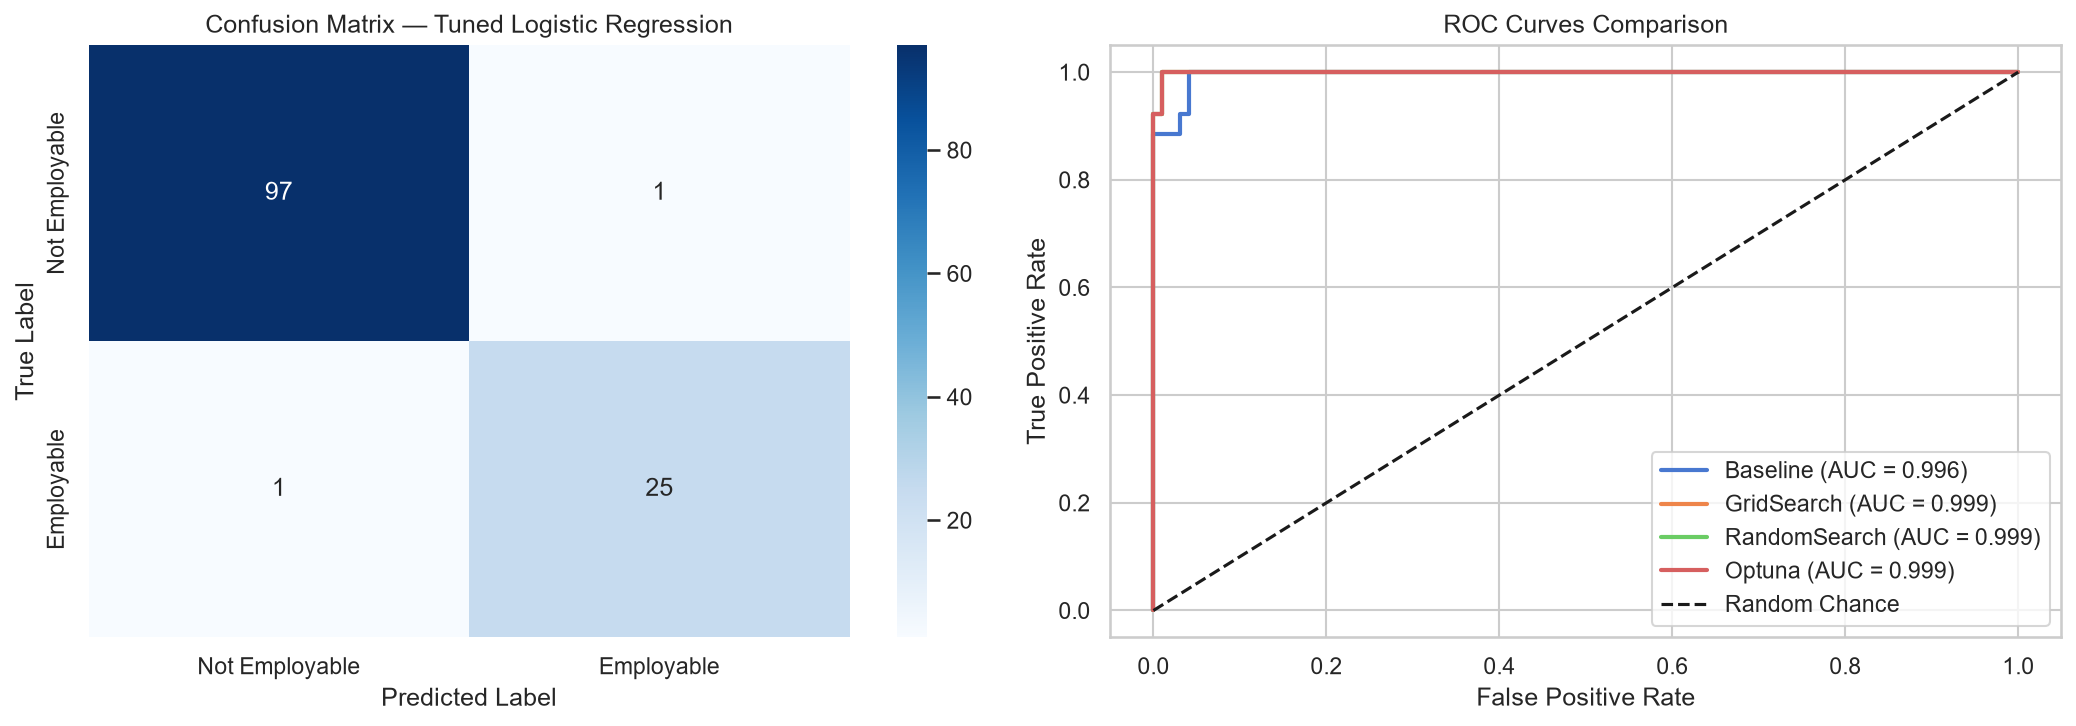

In [ ]:
plt.figure(figsize=(14, 5))

# Subplot 1: Confusion Matrix
plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, y_pred_grid)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Employable', 'Employable'],
            yticklabels=['Not Employable', 'Employable'])
plt.title("Confusion Matrix — Tuned Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Subplot 2: ROC Curves
plt.subplot(1, 2, 2)
for name, prob in [('Baseline', y_proba_base), ('GridSearch', y_proba_grid), ('RandomSearch', y_proba_rand), ('Optuna', y_proba_opt)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance')
plt.title("ROC Curves Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


## 16. Career Recommendation System Demonstration
Testing transparent competency matching on a candidate profile.

In [ ]:
from src.career_recommender import evaluate_career_recommendations

demo_student = {
    'GPA': 8.2,
    'Core_Subject_Score': 78,
    'Programming_Skill': 82,
    'Tool_Proficiency': 76,
    'Domain_Knowledge': 72,
    'Project_Experience': 5,
    'Certification_Count': 3,
    'Internship_Duration': 6,
    'Industry_Relevance': 0.8,
    'Communication_Skill': 68,
    'Teamwork_Ability': 74,
    'Leadership_Potential': 64,
    'Adaptability': 72,
    'Learning_Motivation': 80,
    'Career_Clarity': 70,
    'Market_Awareness': 68,
    'Research_Participation': 0
}

recs = evaluate_career_recommendations(demo_student, top_n=3)
print("=== Top 3 Career Recommendations ===")
for i, r in enumerate(recs, 1):
    print(f"\nRank #{i}: {r['role_title']} ({r['suitability_score']}% Match)")
    print(f"Category: {r['category']}")
    print(f"Identified Skill Gaps: {len(r['skill_gaps'])}")
    for gap in r['skill_gaps']:
        print(f"  - {gap['skill_name']}: Current {gap['student_score']} vs Target {gap['benchmark']} -> {gap['advice']}")


ModuleNotFoundError: No module named 'src'